# 독립 구현 시작 

## M1
1. California housing 데이터를 불러오기 
2. 데이터의 행과 열 개수 출력하기 
3. 상위 5개 행 출력하기 

In [1]:
import pandas as pd 
import numpy as np 

In [2]:
housing = pd.read_csv('housing.csv')

print(housing.head())
print(housing.shape)

   longitude  latitude  housing_median_age  total_rooms  total_bedrooms  \
0    -122.23     37.88                41.0        880.0           129.0   
1    -122.22     37.86                21.0       7099.0          1106.0   
2    -122.24     37.85                52.0       1467.0           190.0   
3    -122.25     37.85                52.0       1274.0           235.0   
4    -122.25     37.85                52.0       1627.0           280.0   

   population  households  median_income  median_house_value ocean_proximity  
0       322.0       126.0         8.3252            452600.0        NEAR BAY  
1      2401.0      1138.0         8.3014            358500.0        NEAR BAY  
2       496.0       177.0         7.2574            352100.0        NEAR BAY  
3       558.0       219.0         5.6431            341300.0        NEAR BAY  
4       565.0       259.0         3.8462            342200.0        NEAR BAY  
(20640, 10)


## M2 - 훈련 & 테스트 데이터 분리 

- 조건 
1. 훈련 데이터 80% 테스트 데이터 20%로 분리하기 
2. median_income을 이용해 income_cat이라는 소득 구간 변수 만들기.
3. income_cat을 기준으로 계층적 샘플링(Stratified Sampling) 수행하기.

In [6]:
from sklearn.model_selection import StratifiedShuffleSplit

split = StratifiedShuffleSplit(n_splits=1, test_size=0.2, random_state=42)

housing["income_cat"] = np.ceil(
    housing["median_income"] / 1.5
).clip(upper = 5.0)

print(housing["income_cat"].value_counts())

# 실제 계층적 분할 

for train_index,test_index in split.split(housing, housing["income_cat"]):
    strat_train_set = housing.loc[train_index]
    strat_test_set = housing.loc[test_index]
#strat_train_set, strat_test_set = split.split(housing, housing["income_cat"])
# 오류 이유: 변수 2개에 값을 나눠 담으려고 했는데 실제로 1개만 반환함 
# 훈련셋과 테스트셋을 직접 반환하는 함수가 아니라 "훈련 인덱스 / 테스트 인덱스의 쌍을 하나씩 생성하는 이터레이터를 반환함"

print(f"strat_train_set: {strat_train_set.shape[0]}")
print(f"strat_test_set: {strat_test_set.shape[0]}")


income_cat
3.0    7236
2.0    6581
4.0    3639
5.0    2362
1.0     822
Name: count, dtype: int64
strat_train_set: 16512
strat_test_set: 4128


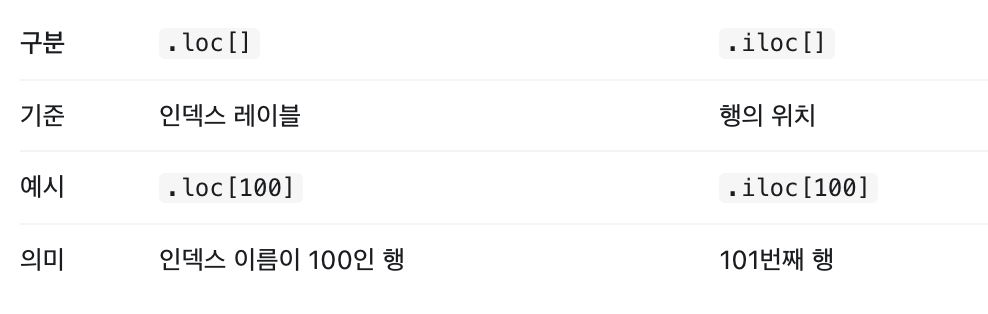

## M3 - 데이터 누수 방지
: 훈련 데이터와 테스트 데이터를 분리했으니, 머신러닝 모델에 넣을 **입력 특성(X)**과 **정답(y)**를 준비해야한다. 

목표: "strat_train_set"에서 다음 두 변수를 만들기 

    - housing : 모델에 입력할 특성 데이터 

    - housing_labels: 모델이 예측해야하는 실제 주택 가격 

조건: 

    1. housing에서는 median_house_value와 income_cat을 제거하기.

    2. housing_labels에는 median_house_value만 저장

    3. 원본 strat_train_set은 변경하지 않기.

In [7]:
housing = strat_train_set.drop(columns = ["median_house_value","income_cat"])
housing_labels = strat_train_set["median_house_value"].copy()

print(f"housing: {housing.shape}")
print(f"housing_labels: {housing_labels.shape}")

housing: (16512, 9)
housing_labels: (16512,)


## M4- 독립 EDA
: 모델 학습하기 전에 데이터의 상태를 확인하는 과정 

1. 각 컬럼의 자료형과 결측치 존재 여부 확인하기 
2. 숫자형 컬럼들의 평균, 표준편차, 최솟값, 최댓값 등 기초 통계량 확인하기
3. ocean_proximity 컬럼에 어떤 범주들이 있고 각각 몇 개씩 있는지 확인하기

In [8]:
housing.info()

<class 'pandas.DataFrame'>
Index: 16512 entries, 12655 to 19773
Data columns (total 9 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   longitude           16512 non-null  float64
 1   latitude            16512 non-null  float64
 2   housing_median_age  16512 non-null  float64
 3   total_rooms         16512 non-null  float64
 4   total_bedrooms      16354 non-null  float64
 5   population          16512 non-null  float64
 6   households          16512 non-null  float64
 7   median_income       16512 non-null  float64
 8   ocean_proximity     16512 non-null  str    
dtypes: float64(8), str(1)
memory usage: 1.4 MB


- total_bedrooms에 결측치 존재
- ocean_proximity 제외 all float

In [9]:
housing.describe()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income
count,16512.000000,16512.000000,16512.000000,16512.000000,16354.000000,16512.000000,16512.000000,16512.000000
mean,-119.575635,35.639314,28.653404,2622.539789,534.914639,1419.687379,497.011810,3.875884
std,2.001828,2.137963,12.574819,2138.417080,412.665649,1115.663036,375.696156,1.904931
min,-124.350000,32.540000,1.000000,6.000000,2.000000,3.000000,2.000000,0.499900
25%,-121.800000,33.940000,18.000000,1443.000000,295.000000,784.000000,279.000000,2.566950
50%,-118.510000,34.260000,29.000000,2119.000000,433.000000,1164.000000,408.000000,3.541550
75%,-118.010000,37.720000,37.000000,3141.000000,644.000000,1719.000000,602.000000,4.745325
max,-114.310000,41.950000,52.000000,39320.000000,6210.000000,35682.000000,5358.000000,15.000100


In [10]:
housing["ocean_proximity"].value_counts()

ocean_proximity
<1H OCEAN     7277
INLAND        5262
NEAR OCEAN    2124
NEAR BAY      1847
ISLAND           2
Name: count, dtype: int64

## M5- 결측치 처리 직접 구현 

- SimpleImputer를 이용해 숫자형 데이터의 결측치를 처리할 것. 

목표:
1. housing에서 숫자형 컬럼만 선택해 housing_num에 저장하기.
2. SimpleImputer 객체를 만들고 strategy="median"으로 설정
3. housing_num으로 중앙값을 학습한 다음 결측치를 변환

In [11]:
 #객체를 만든다 - SimpleImputer는 scikit-learn에서 재공하는 클래스
from sklearn.impute import SimpleImputer
housing_num =  housing.select_dtypes(include=[np.number])   

imputer = SimpleImputer(strategy="median") #중앙값으로 결측치 대체 

housing_num_tr = imputer.fit_transform(housing_num) #fit_transform()은 fit()과 transform()을 동시에 수행


print(housing_num_tr.shape)
print(np.isnan(housing_num_tr).sum())
print(type(housing_num_tr))

(16512, 8)
0
<class 'numpy.ndarray'>


## M-6. 전처리 Pipeline
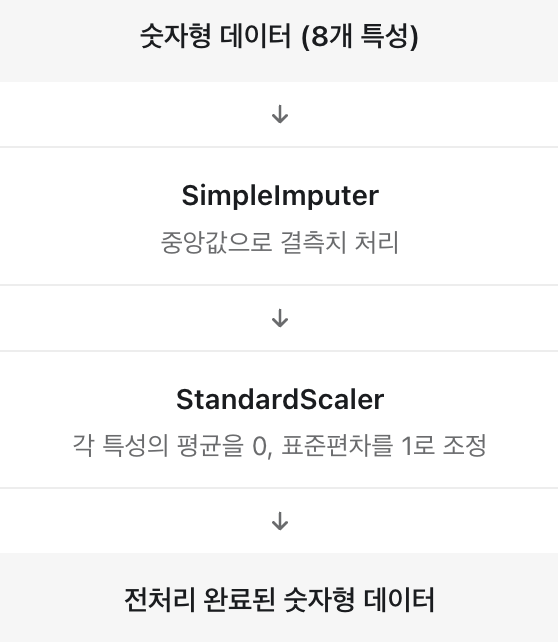

> num_pipeline이라는 변수를 만들고 다음 두 단계 연결 
1. SimpleImputer(Strategy="median")
2. StandardScaler()


In [12]:
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", StandardScaler())
])

print(type(num_pipeline))
print(num_pipeline)

<class 'sklearn.pipeline.Pipeline'>
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler())])


**[Pipeline 변수가 아닌 클래스]**

- Pipeline은 클래스로 여러 처리 단계를 순서대로 연결하는 도구이다. 
- num_pipelined은 변수로, 생성한 Pipeline 객체를 저장하고 
- imputer: 단계 이름으로 결측치 처리 단계를 구분한다

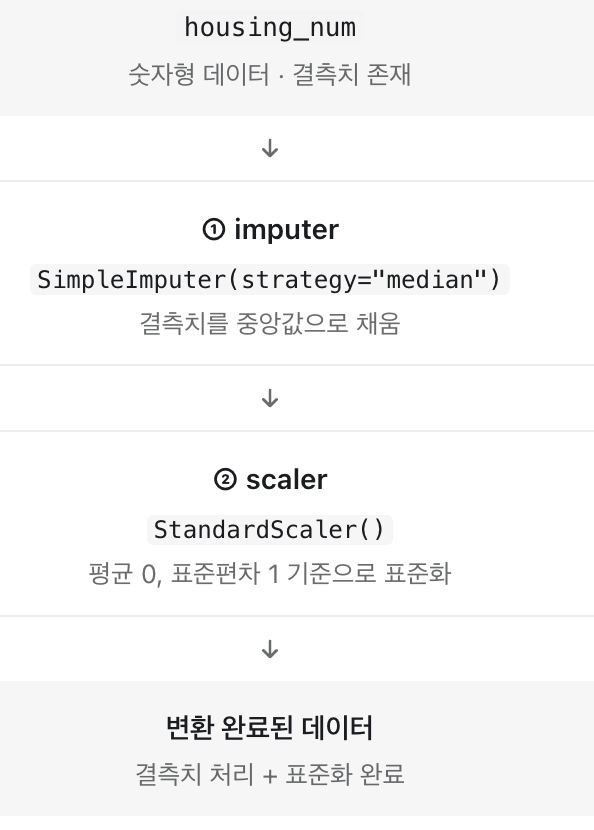

- 원래는 따로 실행될 것을 하나의 박스에 넣어 단계별로 실행 가능하게 해주는 것. 

## M-7. 범주형 데이터 처리 
: "ocean_proximity"

In [13]:
from sklearn.preprocessing import OneHotEncoder

cat_encoder = OneHotEncoder(handle_unknown="ignore")

print(cat_encoder)

OneHotEncoder(handle_unknown='ignore')


In [16]:
# 실제 범주형 데이터를 변환 

x = housing[["ocean_proximity"]]
housing_cat_encoded = cat_encoder.fit_transform(x)

# 인코딩 결과 
print(housing_cat_encoded.shape)
print(cat_encoder.categories_)

(16512, 5)
[array(['<1H OCEAN', 'INLAND', 'ISLAND', 'NEAR BAY', 'NEAR OCEAN'],
      dtype=object)]


## M-8. ColumnTransformer 구축 
> 숫자형 전처리와 범주형 전처리 하나로 합치기 

지금까지) 
- num_pipeline: 결측치 처리 -> 표준화 
- cat_encoder: One-Hot-Encding 

=> **Pipeline**은 작업 순서대로 연결, **ColumnTransformer**는 컬럼에 따라 서로 다른 전처리 적용 

In [17]:
from sklearn.compose import ColumnTransformer

num_features = housing.select_dtypes(include=[np.number]).columns.tolist()
cat_features = housing.select_dtypes(exclude=[np.number]).columns.tolist()

full_pipeline = ColumnTransformer([
    ("num", num_pipeline, num_features),
    ("cat", cat_encoder, cat_features)
])

In [18]:
housing_prepared = full_pipeline.fit_transform(housing)

print(housing_prepared.shape)

(16512, 13)


## M-9. Baseline 모델 구현 
: LinearRegreesion 직접 사용 

In [19]:
from sklearn.linear_model import LinearRegression

lin_reg = LinearRegression()
print(lin_reg)

LinearRegression()


In [21]:
# baseline 모델 학습 및 교차 검증 
lin_pipeline = Pipeline([
    ("preprocessing",full_pipeline),
    ("model",lin_reg)
])

from sklearn.model_selection import cross_val_score
scores = cross_val_score(lin_pipeline,
                 housing, 
                 housing_labels, 
                 cv=5, 
                 scoring="neg_root_mean_squared_error")

rmse_scores = -scores 

print(f"Fold별 RMSE: {rmse_scores}")
print(f"평균 RMSE: {rmse_scores.mean()}")

Fold별 RMSE: [68906.22250988 68244.4822399  69960.78115005 70052.1498968
 68928.34602144]
평균 RMSE: 69218.39636361298


## M-10. RandomForest 독립 구현 

In [22]:
from sklearn.ensemble import RandomForestRegressor

rf_reg = RandomForestRegressor(n_estimators=100, random_state=42)

full_pipeline_rf = Pipeline([
    ("preprocessing",full_pipeline),
    ("model",rf_reg)
])

rf_scores = cross_val_score(full_pipeline_rf,
                 housing, 
                 housing_labels, 
                 cv=5, 
                 scoring="neg_root_mean_squared_error")

rf_rmse_scores = -rf_scores 

print(f"Fold별 RMSE: {rf_rmse_scores}")
print(f"평균 RMSE: {rf_rmse_scores.mean()}")


Fold별 RMSE: [50111.50404424 48860.19537951 49226.40439387 50718.22799487
 50789.57263693]
평균 RMSE: 49941.180889884025


## M-11. 전처리 실험 
> 전처리 방법을 하나 바꿨을 때 성능이 달라지는지?

**Standard scaler 대신, Robust Scaler***
- StandardScaler: 평균과 표준편차를 사용
- RobustScaler: 중앙값과 사분위 범위를 사용하므로 이상치의 영향을 덜 받음

In [24]:
from sklearn.preprocessing import RobustScaler

robust_num_pipeline = Pipeline([
    ("imputer", SimpleImputer(strategy="median")),
    ("scaler", RobustScaler())
])

robust_full_pipeline = ColumnTransformer([
    ("num", robust_num_pipeline, num_features),
    ("cat", cat_encoder, cat_features)
])

# Linear regression 유지:
# 우리가 알고 싶은 건 StandardScaler와 RobustScaler 중 어느 쪽이 이 모델에 더 적합한가? 모델까지 바꾸면 성능 차이가 전처리 때문인지 모델 때문인지 구분하기 어려워
robust_lin_pipeline = Pipeline([
    ("preprocessing",robust_full_pipeline),
    ("model",lin_reg)   
])

robust_lin_scores = cross_val_score(robust_lin_pipeline,
                 housing, 
                 housing_labels, 
                 cv=5, 
                 scoring="neg_root_mean_squared_error") 
robust_lin_rmse_scores = -robust_lin_scores

print(f"Fold별 RMSE: {robust_lin_rmse_scores}")
print(f"평균 RMSE: {robust_lin_rmse_scores.mean()}")



Fold별 RMSE: [68906.22250988 68244.4822399  69960.78115005 70052.1498968
 68928.34602144]
평균 RMSE: 69218.396363613


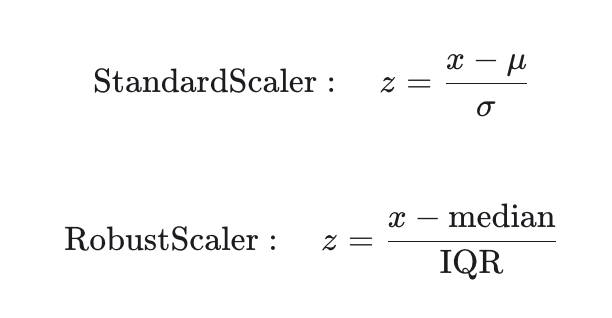


결론: 이번 데이터와 Linear Regression 모델에서는 RobustScaler로 변경해도 예측 성능이 개선되지 않았다.


두 스켈일러 변환 방식이 다르지만, 일반적인 LinearRegression은 절편과 회귀계수 자유롭게 조정 가능 즉, 입력값의 크기와 중심이 바뀌더라도, 회귀계수가 그 변화를 보상해서 같은 예측값을 만들 수 있는 것

!= 스켈일러가 아무 역할을 하지 않았다 but 서로 다른 변환 수행했지만 최종 예측 결과가 같았다. 

> StandardScaler와 RobustScaler를 비교한 결과, Linear Regression의 5-Fold CV RMSE는 모두 약 $69,218로 동일했다. 이는 절편을 포함하는 비정규화 선형회귀가 특성별 선형 스케일 변환에 대해 예측 불변성을 갖는다는 이론과 일치한다.